# Grant figures

Code to regenerate four poster figures:

1. `combined_human_11_target_reward_trajectories_poster_nofit.png`: human_11, session 0, blocks 0/1/3. Target area, time to reward, force trajectories.
2. `combined_human_11_target_reward_trajectories_poster.png`: same as (1), plus a dashed exponential-decay fit on the time-to-reward panels.
3. `combined_target_reward_trajectories_colored_20g_firstlast_poster.png`: mouse M029, session 25, blocks 1/2/3, first 2 + last 2 trials of each block.
4. `trial14_lickport_vs_force_overlay_thick.png`: M029, session 25, trial 14. Lick port position over time, and the force trajectory overlaid on the target area.

**Requirements**
- Run from inside the `NDNF-pipeline` repository (it imports `ndnf_pipeline`).
- A `dj_local_conf.json` at the repository root with DataJoint credentials for the lab database.

Figures are saved as 300-dpi PNGs to `Notebooks/figures/grant/`.

**Colour conventions**
- *Target area*: reward-port speed as a function of the applied force vector (viridis; brighter means faster).
- *Time to reward / force trajectories*: the highlighted trials go blue to red, earliest to latest. Gray dots are trials that are not shown in the trajectory row.

## Setup

In [1]:
from pathlib import Path
import sys

repo_root = next((parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (parent / 'ndnf_pipeline').exists()), None)
if repo_root is None:
    raise RuntimeError('Could not locate the repository root')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import datajoint as dj
dj.config.load(str(repo_root / 'dj_local_conf.json'))
dj.conn()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
from ndnf_pipeline import experiment
from ndnf_pipeline.plot import behavior_plots as bp

out_dir = repo_root / 'Notebooks' / 'figures' / 'grant'
out_dir.mkdir(parents=True, exist_ok=True)

# poster-scale text sizes
FONT_LABEL = 44
FONT_TITLE = 56
FONT_TRIAL_TITLE = 48
FONT_LEGEND = 34

C:\NDNF-pipeline\.venv\Lib\site-packages\datajoint\plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # requires setuptools<82


[2026-10-05 01:15:42,133][INFO]: DataJoint is configured from C:\NDNF-pipeline\dj_local_conf.json


[2026-10-05 01:15:42,756][INFO]: DataJoint 0.14.9 connected to rozmar@datajoint.ndnf.koki.hun-ren.hu:3306


## Shared helpers

- **Force traces**: the two load-cell axes are converted to Left-Right / Posterior-Anterior (g). Each trial is gaussian-filtered (sigma = 3 ms) and restricted to the response epoch, from the go cue to the threshold crossing.
- **Baseline**: for M029, the median over all of the selected trials is subtracted. For human_11, each trial's own quiescence-period median is subtracted instead, because the human data drift more between trials.
- **Exponential fit**: `c + a * exp(-x / tau)`, fitted to time to reward against trial number within each block.

In [2]:
def lr_pa_traces_for_trials(subject_id, session, block, trials, filter_sigma_ms=3.0, epochs=('response',)):
    # Baseline = median over all selected trials (used for M029)
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id')
    _, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)

    trial_restriction = [{'trial': int(t)} for t in trials]
    f0_query = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                * experiment.BehaviorTrial() * experiment.Block() & {**key, 'force_axis_idx': 0} & trial_restriction)
    f1_query = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() * experiment.Block()
                & {**key, 'force_axis_idx': 1} & trial_restriction)
    force_trials, force_trace_times, f0_ = f0_query.fetch('trial', 'force_trace_time', 'force_trace_value', order_by='trial')
    f1_ = f1_query.fetch('force_trace_value', order_by='trial')
    f0_baseline = np.median(np.concatenate(f0_))
    f1_baseline = np.median(np.concatenate(f1_))
    f0 = [f - f0_baseline for f in f0_]
    f1 = [f - f1_baseline for f in f1_]
    lr_traces, pa_traces = bp._lr_pa_traces(f0, f1, lr_idx, pa_idx, lr_sign, pa_sign)

    sample_interval_s = bp._estimate_sample_interval(force_trace_times)
    filter_sigma = bp.ms_to_samples_float(filter_sigma_ms, sample_interval_s, minimum=1e-6)
    lr_traces, pa_traces = bp._filter_traces(lr_traces, pa_traces, 'gaussian', sigma=filter_sigma)

    epoch_windows = bp._fetch_epoch_windows(experiment, key)
    lr_traces, pa_traces = bp._filter_traces_by_epochs(force_trials, force_trace_times, lr_traces, pa_traces,
                                                        epoch_windows, epochs)
    return lr_traces, pa_traces


def lr_pa_traces_quiescence_baseline(subject_id, session, block, trials, filter_sigma_ms=3.0, epochs=('response',)):
    # Baseline = each trial's own quiescence-period median (used for human_11)
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id')
    _, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)

    trial_restriction = [{'trial': int(t)} for t in trials]
    f0_query = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                * experiment.BehaviorTrial() * experiment.Block() & {**key, 'force_axis_idx': 0} & trial_restriction)
    f1_query = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() * experiment.Block()
                & {**key, 'force_axis_idx': 1} & trial_restriction)
    force_trials, force_trace_times, f0_ = f0_query.fetch('trial', 'force_trace_time', 'force_trace_value', order_by='trial')
    f1_ = f1_query.fetch('force_trace_value', order_by='trial')

    go_by_trial = bp._event_time_by_trial(experiment, key, 'go')
    f0, f1 = [], []
    for trial, t, v0, v1 in zip(force_trials, force_trace_times, f0_, f1_):
        t = np.asarray(t, float)
        v0 = np.asarray(v0, float)
        v1 = np.asarray(v1, float)
        go_t = go_by_trial.get(int(trial))
        q_mask = (t < go_t) if go_t is not None else np.zeros_like(t, dtype=bool)
        if q_mask.any():
            b0, b1 = np.median(v0[q_mask]), np.median(v1[q_mask])
        else:
            b0, b1 = np.median(v0), np.median(v1)
        f0.append(v0 - b0)
        f1.append(v1 - b1)

    lr_traces, pa_traces = bp._lr_pa_traces(f0, f1, lr_idx, pa_idx, lr_sign, pa_sign)

    sample_interval_s = bp._estimate_sample_interval(force_trace_times)
    filter_sigma = bp.ms_to_samples_float(filter_sigma_ms, sample_interval_s, minimum=1e-6)
    lr_traces, pa_traces = bp._filter_traces(lr_traces, pa_traces, 'gaussian', sigma=filter_sigma)

    epoch_windows = bp._fetch_epoch_windows(experiment, key)
    lr_traces, pa_traces = bp._filter_traces_by_epochs(force_trials, force_trace_times, lr_traces, pa_traces,
                                                        epoch_windows, epochs)
    return lr_traces, pa_traces


def fetch_target_lut(subject_id, session, block):
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1(
        'task_setting_id', 'target_force_lut')
    force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)
    lut, lut_extent, _, _ = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
    return lut, lut_extent


def fetch_time_to_reward(subject_id, session, blocks):
    # response duration (go cue -> threshold crossing) per trial, sorted by trial
    trials_parts, response_parts = [], []
    for block in blocks:
        key = {'subject_id': subject_id, 'session': session, 'block': block}
        t, _, r = bp._fetch_quiescence_response(experiment, key)
        trials_parts.append(t)
        response_parts.append(r)
    trials = np.concatenate(trials_parts)
    response_value = np.concatenate(response_parts)
    order = np.argsort(trials)
    return trials[order], response_value[order]


def exp_decay(x, a, tau, c):
    return c + a * np.exp(-x / tau)


def fit_exponential_trend(trials, response_value):
    x = trials - trials.min()
    p0 = [max(response_value.max() - response_value.min(), 1e-3), max(len(x) / 3, 1.0), max(response_value.min(), 1e-3)]
    try:
        popt, _ = curve_fit(exp_decay, x, response_value, p0=p0, maxfev=10000,
                             bounds=([0, 1e-3, 0], [np.inf, np.inf, np.inf]))
        return popt
    except RuntimeError:
        return None

## Combined figure builder (figures 1-3)

The figure has three rows and one column per block:
1. **Target area**: the block's target LUT on a shared colour scale. The block name is written above each column.
2. **Time to reward**, log scale. Trials shown in row 3 are coloured blue to red. All other trials are gray. With `show_fit=True`, a faint dashed exponential fit is drawn, and unselected dots are a darker gray.
3. **Force trajectories** of the selected trials, coloured blue to red in trial order.

In [3]:
def build_combined_figure(subject_id, session, columns, force_range, trace_fn, out_name,
                          show_fit=False, x_nbins=7):
    '''columns: list of dicts with keys
         label         - column header
         lut_block     - block whose target LUT is drawn in row 0
         reward_blocks - block(s) whose trials are plotted in row 1
         traj_block    - block whose force traces are drawn in row 2
         trials        - trials highlighted in row 1 and drawn in row 2
    '''
    fig = plt.figure(figsize=(34, 30))
    gs = plt.GridSpec(3, 3, figure=fig, width_ratios=[1, 1, 1],
                       height_ratios=[1, 1, 1], hspace=0.35, wspace=0.3)

    # --- row 0: target area ---
    lut_data = [fetch_target_lut(subject_id, session, c['lut_block']) for c in columns]
    lut_vmin = min(np.min(l) for l, _ in lut_data)
    lut_vmax = max(np.max(l) for l, _ in lut_data)
    for col, (c, (lut, lut_extent)) in enumerate(zip(columns, lut_data)):
        ax = fig.add_subplot(gs[0, col])
        lut_disp = bp._pad_lut_to_range(lut, lut_extent, force_range)
        ax.imshow(lut_disp, extent=force_range, origin='lower', cmap='viridis',
                  aspect='auto', vmin=lut_vmin, vmax=lut_vmax)
        ax.set_xlim(force_range[:2])
        ax.set_ylim(force_range[2:])
        ax.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
        ax.tick_params(labelsize=FONT_LABEL)
        if col == 0:
            ax.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
        pos = ax.get_position()
        fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.012, c['label'], ha='center', va='bottom', fontsize=FONT_TITLE)

    # --- row 1: time to reward (log scale) ---
    group_data = [fetch_time_to_reward(subject_id, session, c['reward_blocks']) for c in columns]
    all_response = np.concatenate([r for _, r in group_data])
    ymin, ymax = all_response.min(), all_response.max()

    axes_reward = []
    fit_handle = None
    for col, (c, (trials, response_value)) in enumerate(zip(columns, group_data)):
        ax = fig.add_subplot(gs[1, col], sharey=axes_reward[0] if axes_reward else None)
        sel_trials = c['trials']
        frac_by_trial = {t: i / max(len(sel_trials) - 1, 1) for i, t in enumerate(sel_trials)}
        is_selected = np.array([t in frac_by_trial for t in trials])
        selected_colors = [bp.cm.coolwarm(frac_by_trial[t]) for t in trials[is_selected]]
        if show_fit:
            popt = fit_exponential_trend(trials, response_value)
            if popt is not None:
                x_fit = np.linspace(trials.min(), trials.max(), 200)
                y_fit = exp_decay(x_fit - trials.min(), *popt)
                fit_handle, = ax.plot(x_fit, y_fit, '--', color='black', alpha=0.35, linewidth=3, zorder=1,
                                       label='exponential fit')
            ax.scatter(trials[~is_selected], response_value[~is_selected], color=(0.45, 0.45, 0.45, 1.0),
                       s=280, alpha=0.9, edgecolor='none', zorder=2)
            ax.scatter(trials[is_selected], response_value[is_selected], c=selected_colors,
                       s=230, alpha=0.9, edgecolor='none', zorder=3)
        else:
            dot_colors = [bp.cm.coolwarm(frac_by_trial[t]) if t in frac_by_trial else (0.8, 0.8, 0.8, 1.0)
                          for t in trials]
            ax.scatter(trials, response_value, c=dot_colors, s=230, alpha=0.9, edgecolor='none', zorder=2)
        ax.set_xlabel('Trial', fontsize=FONT_LABEL)
        ax.set_yscale('log')
        ax.set_ylim(ymin / 1.5, ymax * 4)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=x_nbins))
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(labelsize=FONT_LABEL)
        if col == 0:
            ax.set_ylabel('Time to Reward (s)', fontsize=FONT_LABEL)
        else:
            plt.setp(ax.get_yticklabels(), visible=False)
        axes_reward.append(ax)
    if fit_handle is not None:
        axes_reward[-1].legend(handles=[fit_handle], loc='upper right', fontsize=FONT_LEGEND, frameon=True)

    # --- row 2: force trajectories of the selected trials ---
    for col, c in enumerate(columns):
        ax = fig.add_subplot(gs[2, col])
        lr_traces, pa_traces = trace_fn(subject_id, session, c['traj_block'], c['trials'])
        n_traj = len(lr_traces)
        for i, (lr, pa) in enumerate(zip(lr_traces, pa_traces)):
            ax.plot(lr, pa, '-', color=bp.cm.coolwarm(i / max(n_traj - 1, 1)), alpha=0.5, linewidth=2.5)
        ax.set_xlim(force_range[:2])
        ax.set_ylim(force_range[2:])
        ax.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
        ax.set_title(f"trials {c['trials']}", fontsize=FONT_TRIAL_TITLE)
        ax.tick_params(labelsize=FONT_LABEL)
        if col == 0:
            ax.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)

    out_path = out_dir / out_name
    fig.savefig(out_path, dpi=300, bbox_inches='tight')
    print('Saved to', out_path)
    plt.show()

## Figures 1 & 2: human_11, session 0, blocks 0 / 1 / 3

Each column is one raw block. Blocks 0 and 1 highlight their first 2 and last 2 trials. Block 3 uses hand-picked trials 78, 79, 100, 101. Force range is ±45 g.

In [4]:
subject_id_h11 = 'human_11'
session_h11 = 0
force_range_h11 = np.array([-1, 1, -1, 1]) * 45  # g
blocks_h11 = [('Block 0', 0), ('Block 1', 1), ('Block 3', 3)]

columns_h11 = []
for label, block in blocks_h11:
    trials, _ = fetch_time_to_reward(subject_id_h11, session_h11, [block])
    columns_h11.append({'label': label, 'lut_block': block, 'reward_blocks': [block], 'traj_block': block,
                        'trials': sorted(trials[:2].tolist() + trials[-2:].tolist())})
columns_h11[2]['trials'] = [78, 79, 100, 101]  # hand-picked for the last block

### Figure 1: without the exponential fit

Saved to

C:\NDNF-pipeline\Notebooks\figures\grant\combined_human_11_target_reward_trajectories_poster_nofit.png

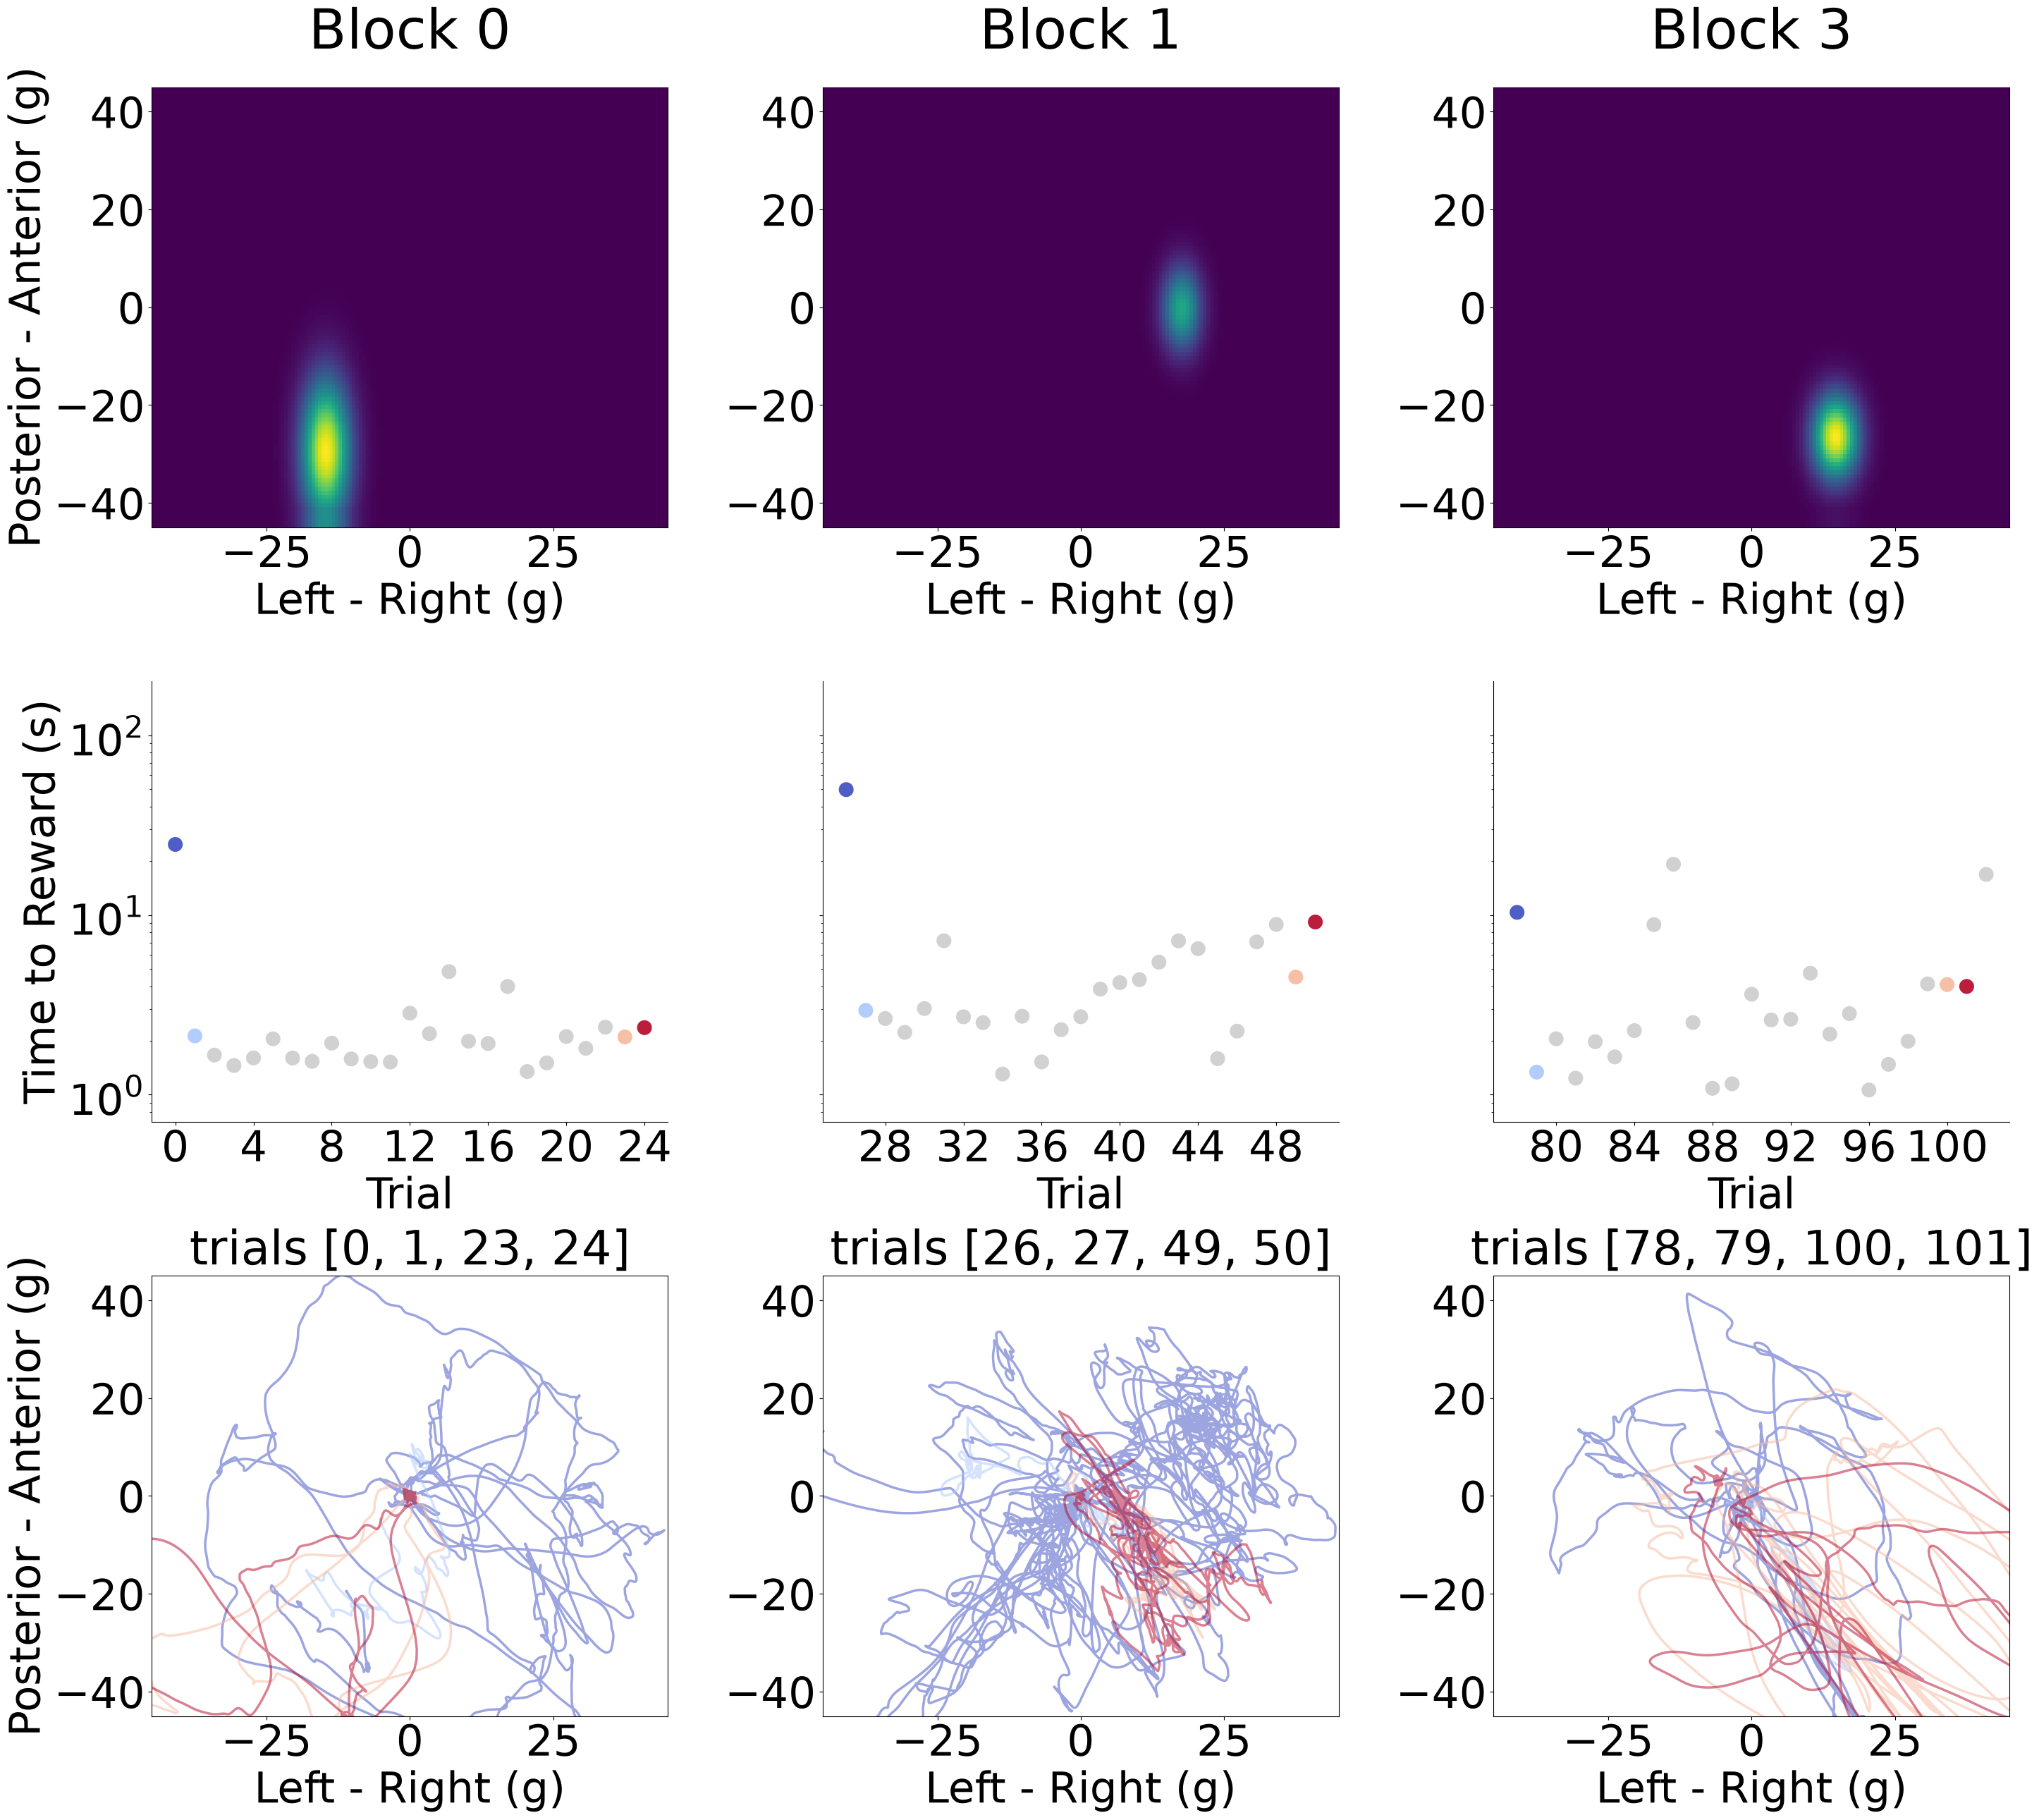

In [5]:
build_combined_figure(subject_id_h11, session_h11, columns_h11, force_range_h11,
                      lr_pa_traces_quiescence_baseline,
                      'combined_human_11_target_reward_trajectories_poster_nofit.png',
                      show_fit=False, x_nbins=7)

### Figure 2: with the exponential fit

Saved to

C:\NDNF-pipeline\Notebooks\figures\grant\combined_human_11_target_reward_trajectories_poster.png

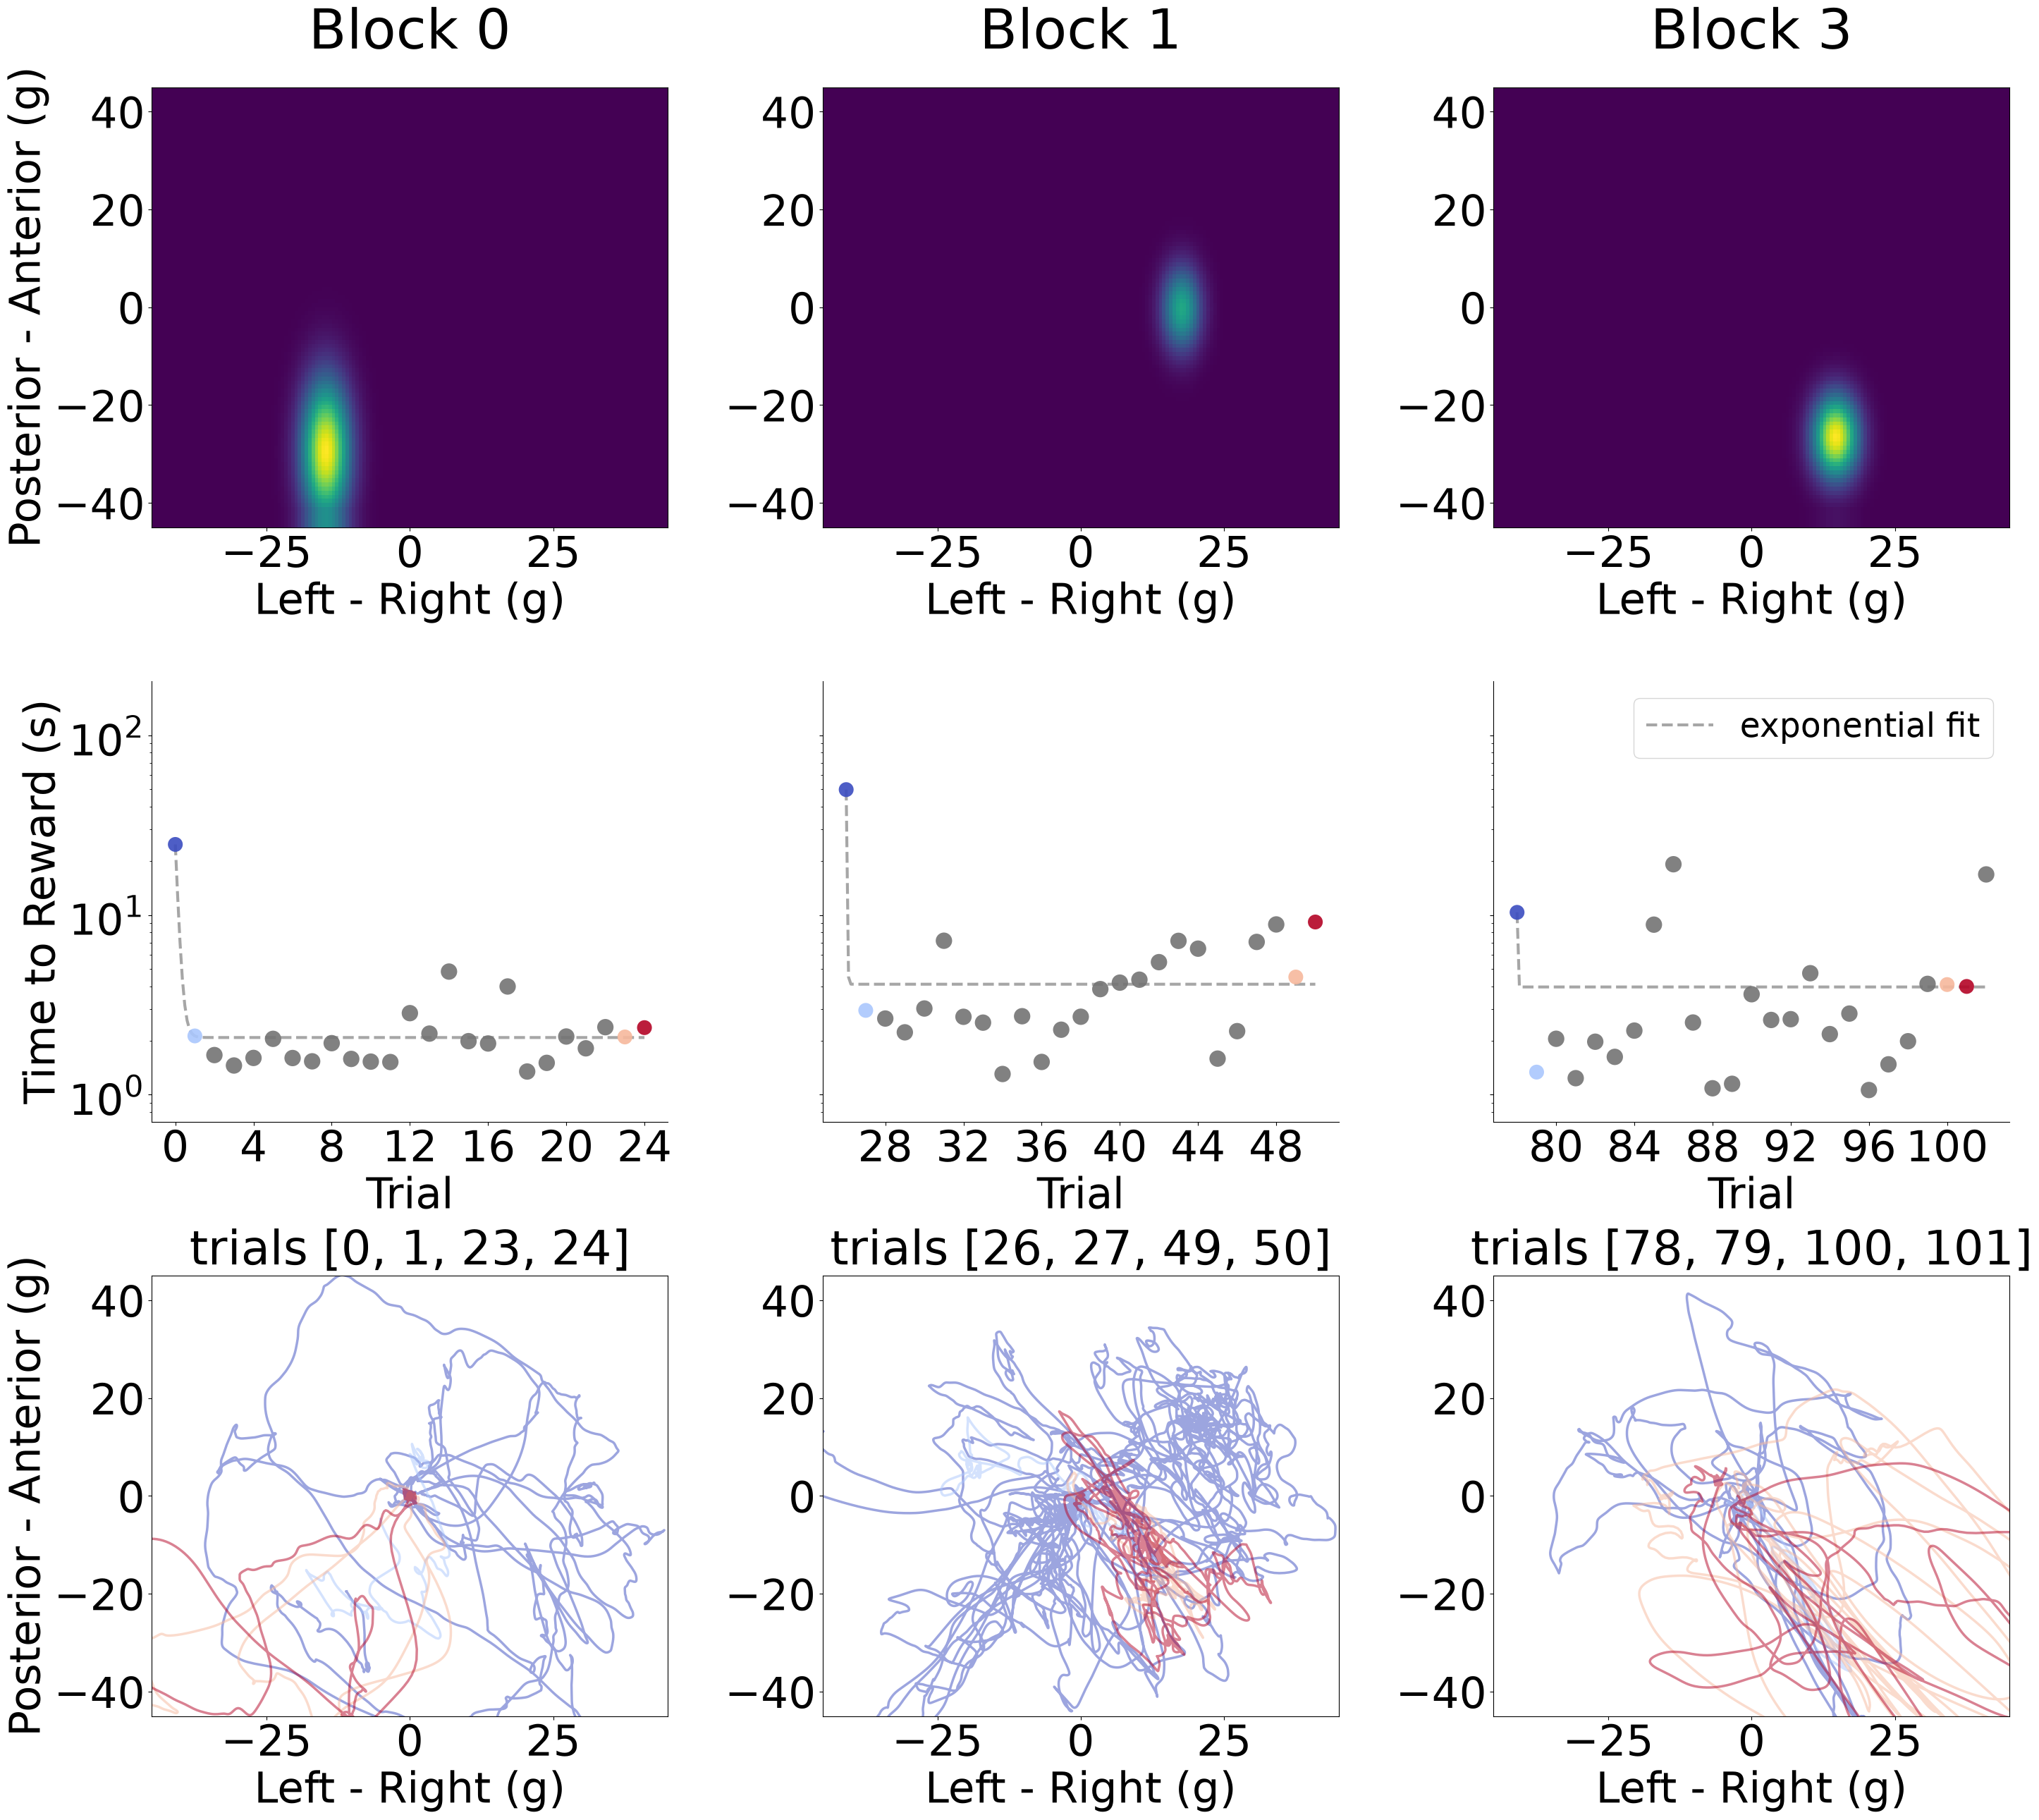

In [6]:
build_combined_figure(subject_id_h11, session_h11, columns_h11, force_range_h11,
                      lr_pa_traces_quiescence_baseline,
                      'combined_human_11_target_reward_trajectories_poster.png',
                      show_fit=True, x_nbins=7)

## Figure 3: M029, session 25, blocks 1 / 2 / 3, first + last 2 trials

The "Block 1" column merges raw blocks 0 and 1 (trials 0-13). Block 2 is trials 14-20 and block 3 is trials 21-27. Each column highlights the first 2 and last 2 trials of its block. Force range is ±20 g.

Saved to

C:\NDNF-pipeline\Notebooks\figures\grant\combined_target_reward_trajectories_colored_20g_firstlast_poster.png

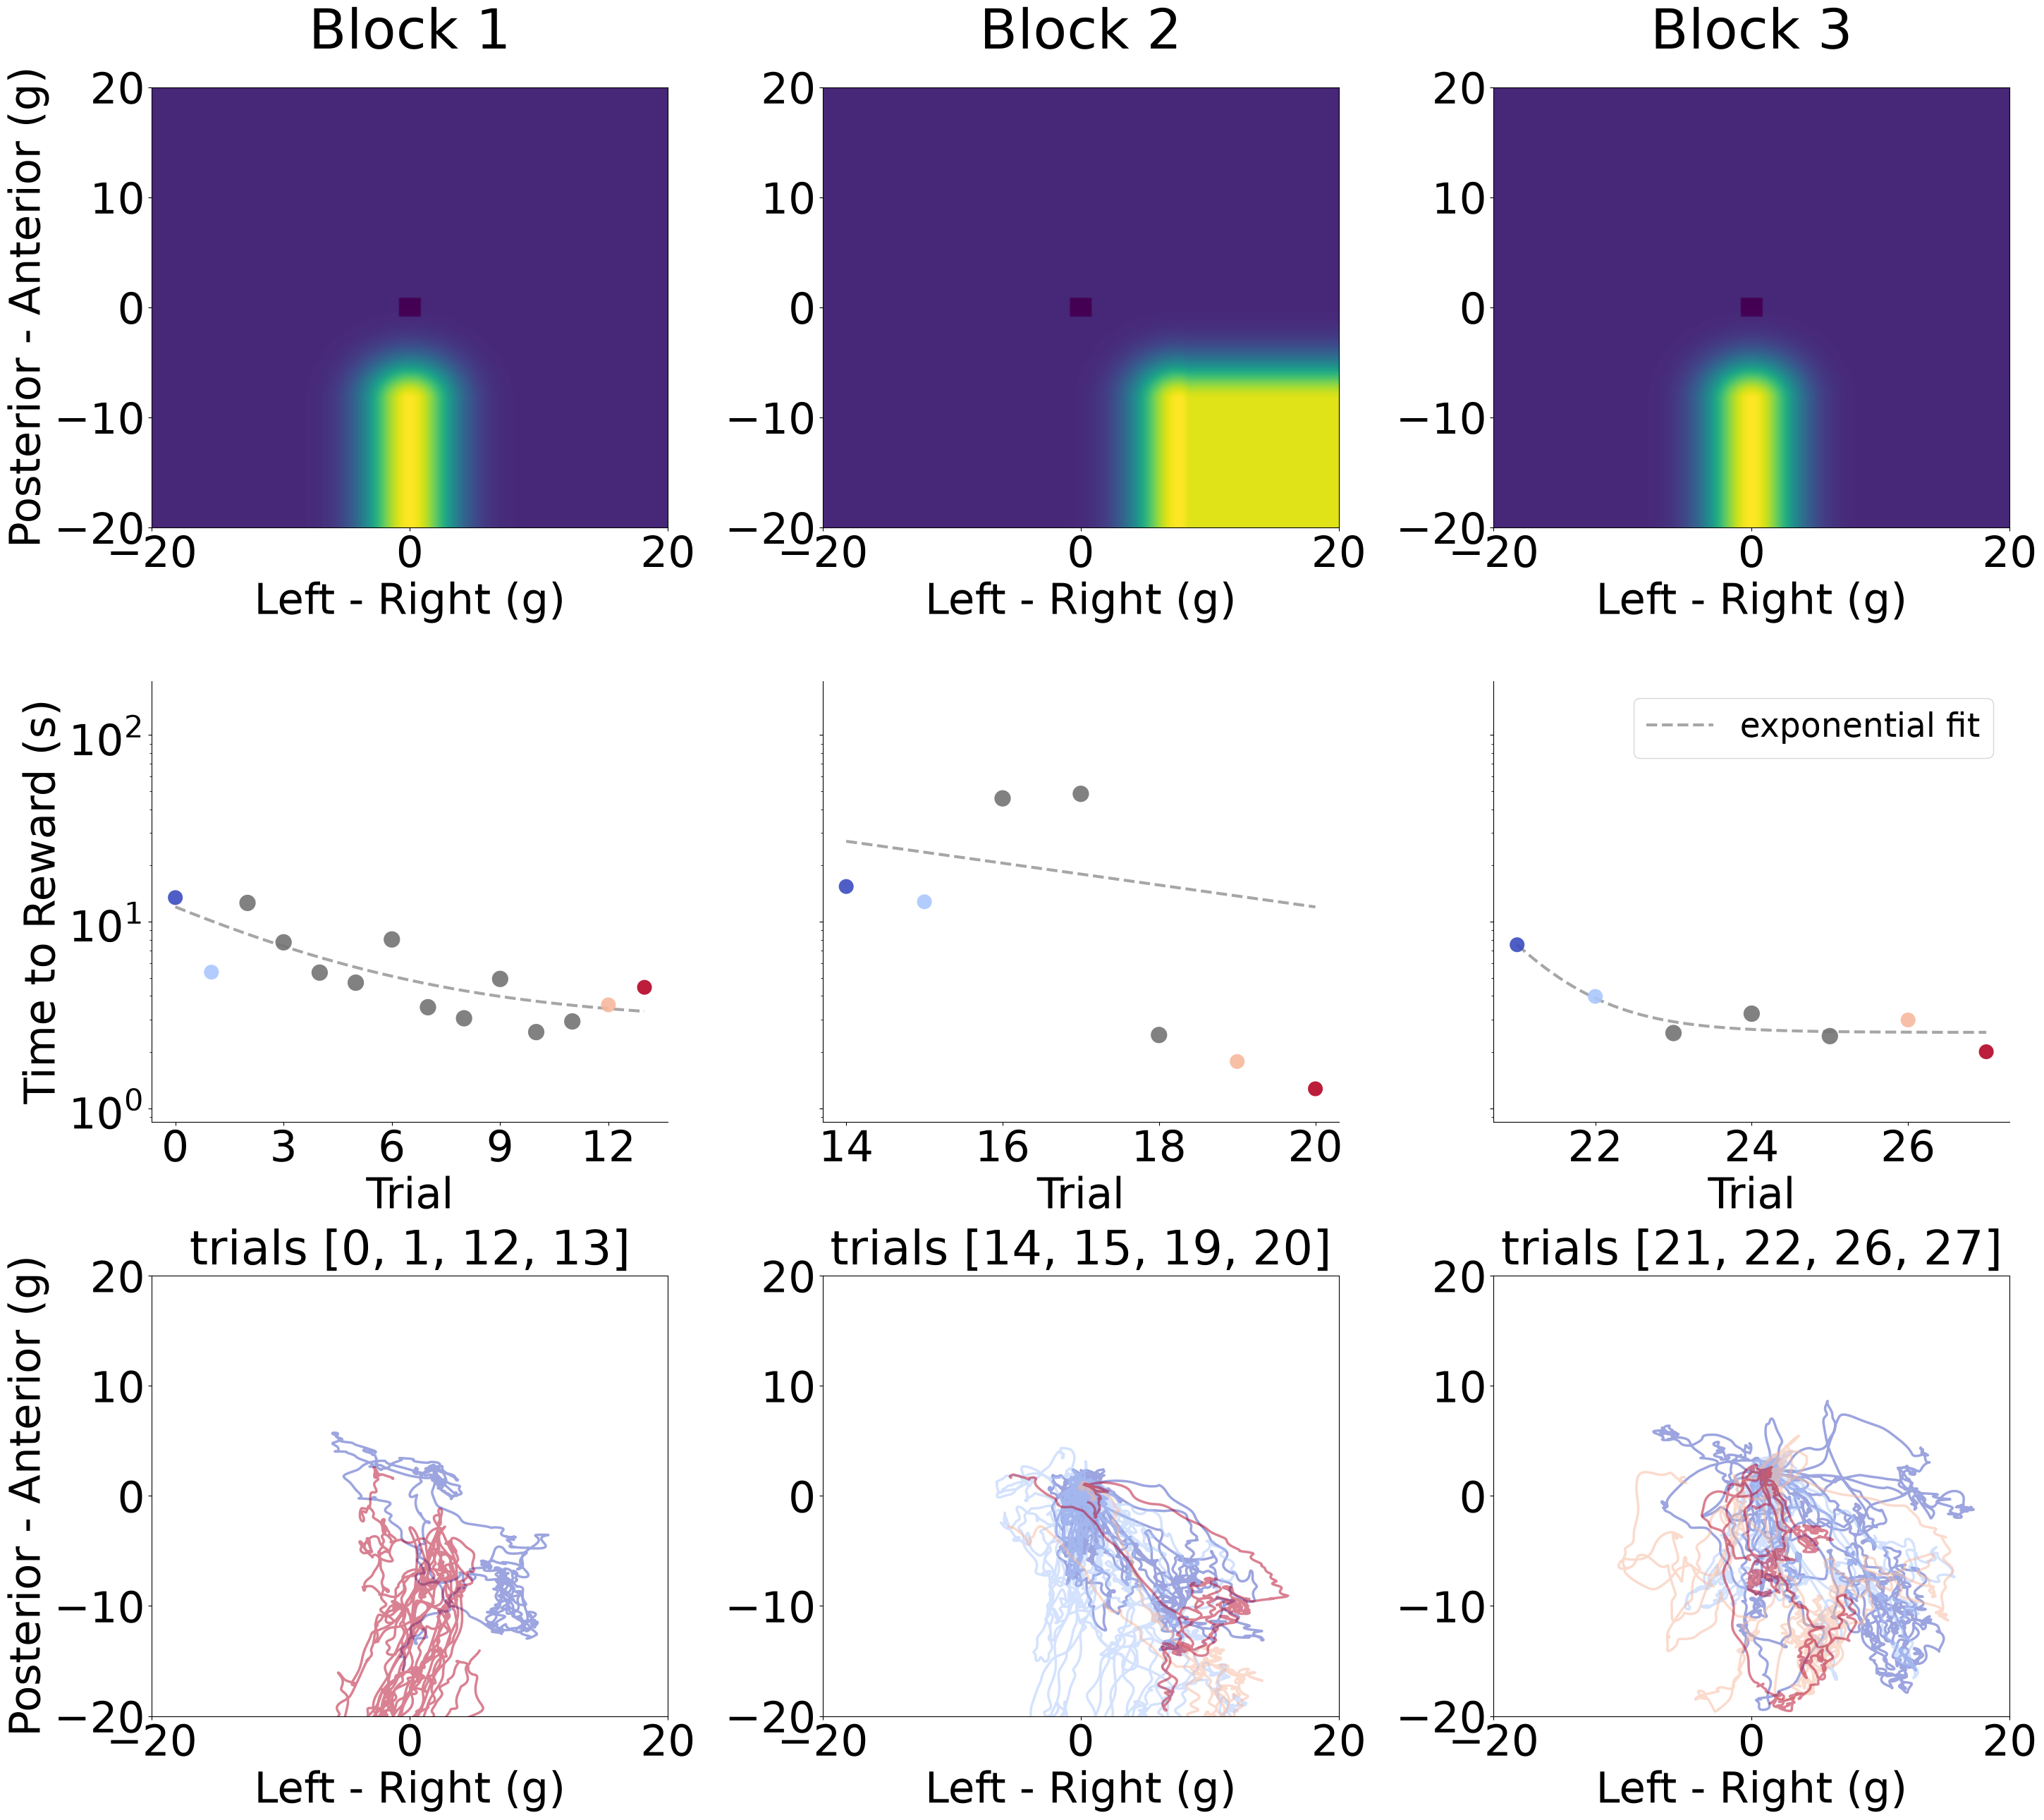

In [7]:
subject_id_m029 = 'M029'
session_m029 = 25
force_range_20g = np.array([-1, 1, -1, 1]) * 20  # g

# NOTE: the original poster draws block 3's target LUT in the 'Block 1' column (lut_block=3).
# Kept here so the output matches the saved poster figure.
columns_m029 = [
    {'label': 'Block 1', 'lut_block': 3, 'reward_blocks': [0, 1], 'traj_block': 1, 'trials': [0, 1, 12, 13]},
    {'label': 'Block 2', 'lut_block': 2, 'reward_blocks': [2],    'traj_block': 2, 'trials': [14, 15, 19, 20]},
    {'label': 'Block 3', 'lut_block': 3, 'reward_blocks': [3],    'traj_block': 3, 'trials': [21, 22, 26, 27]},
]

build_combined_figure(subject_id_m029, session_m029, columns_m029, force_range_20g,
                      lr_pa_traces_for_trials,
                      'combined_target_reward_trajectories_colored_20g_firstlast_poster.png',
                      show_fit=True, x_nbins=6)

## Figure 4: M029, session 25, trial 14. Lick port movement and force trajectory on the target area

**Left panel: lick port position against session time (175-187 s).** The window covers trial 14's response and reward epochs, then trial 15's quiescence.
- Background shading: response (gold), reward (green), quiescence (gray).
- Dashed line: the reward threshold.
- Ticks along the top: licks.
- Trace colour: red marks step-like movement, where smoothed lick-port speed is above its 75th percentile in the window. Blue marks continuous movement.

**Right panel: force trajectory on the target area.** The trial 14 force trajectory (gaussian-filtered, sigma = 3 ms) is drawn on top of block 2's target-area heatmap, up to the threshold crossing.

Saved to

C:\NDNF-pipeline\Notebooks\figures\grant\trial14_lickport_vs_force_overlay_thick.png

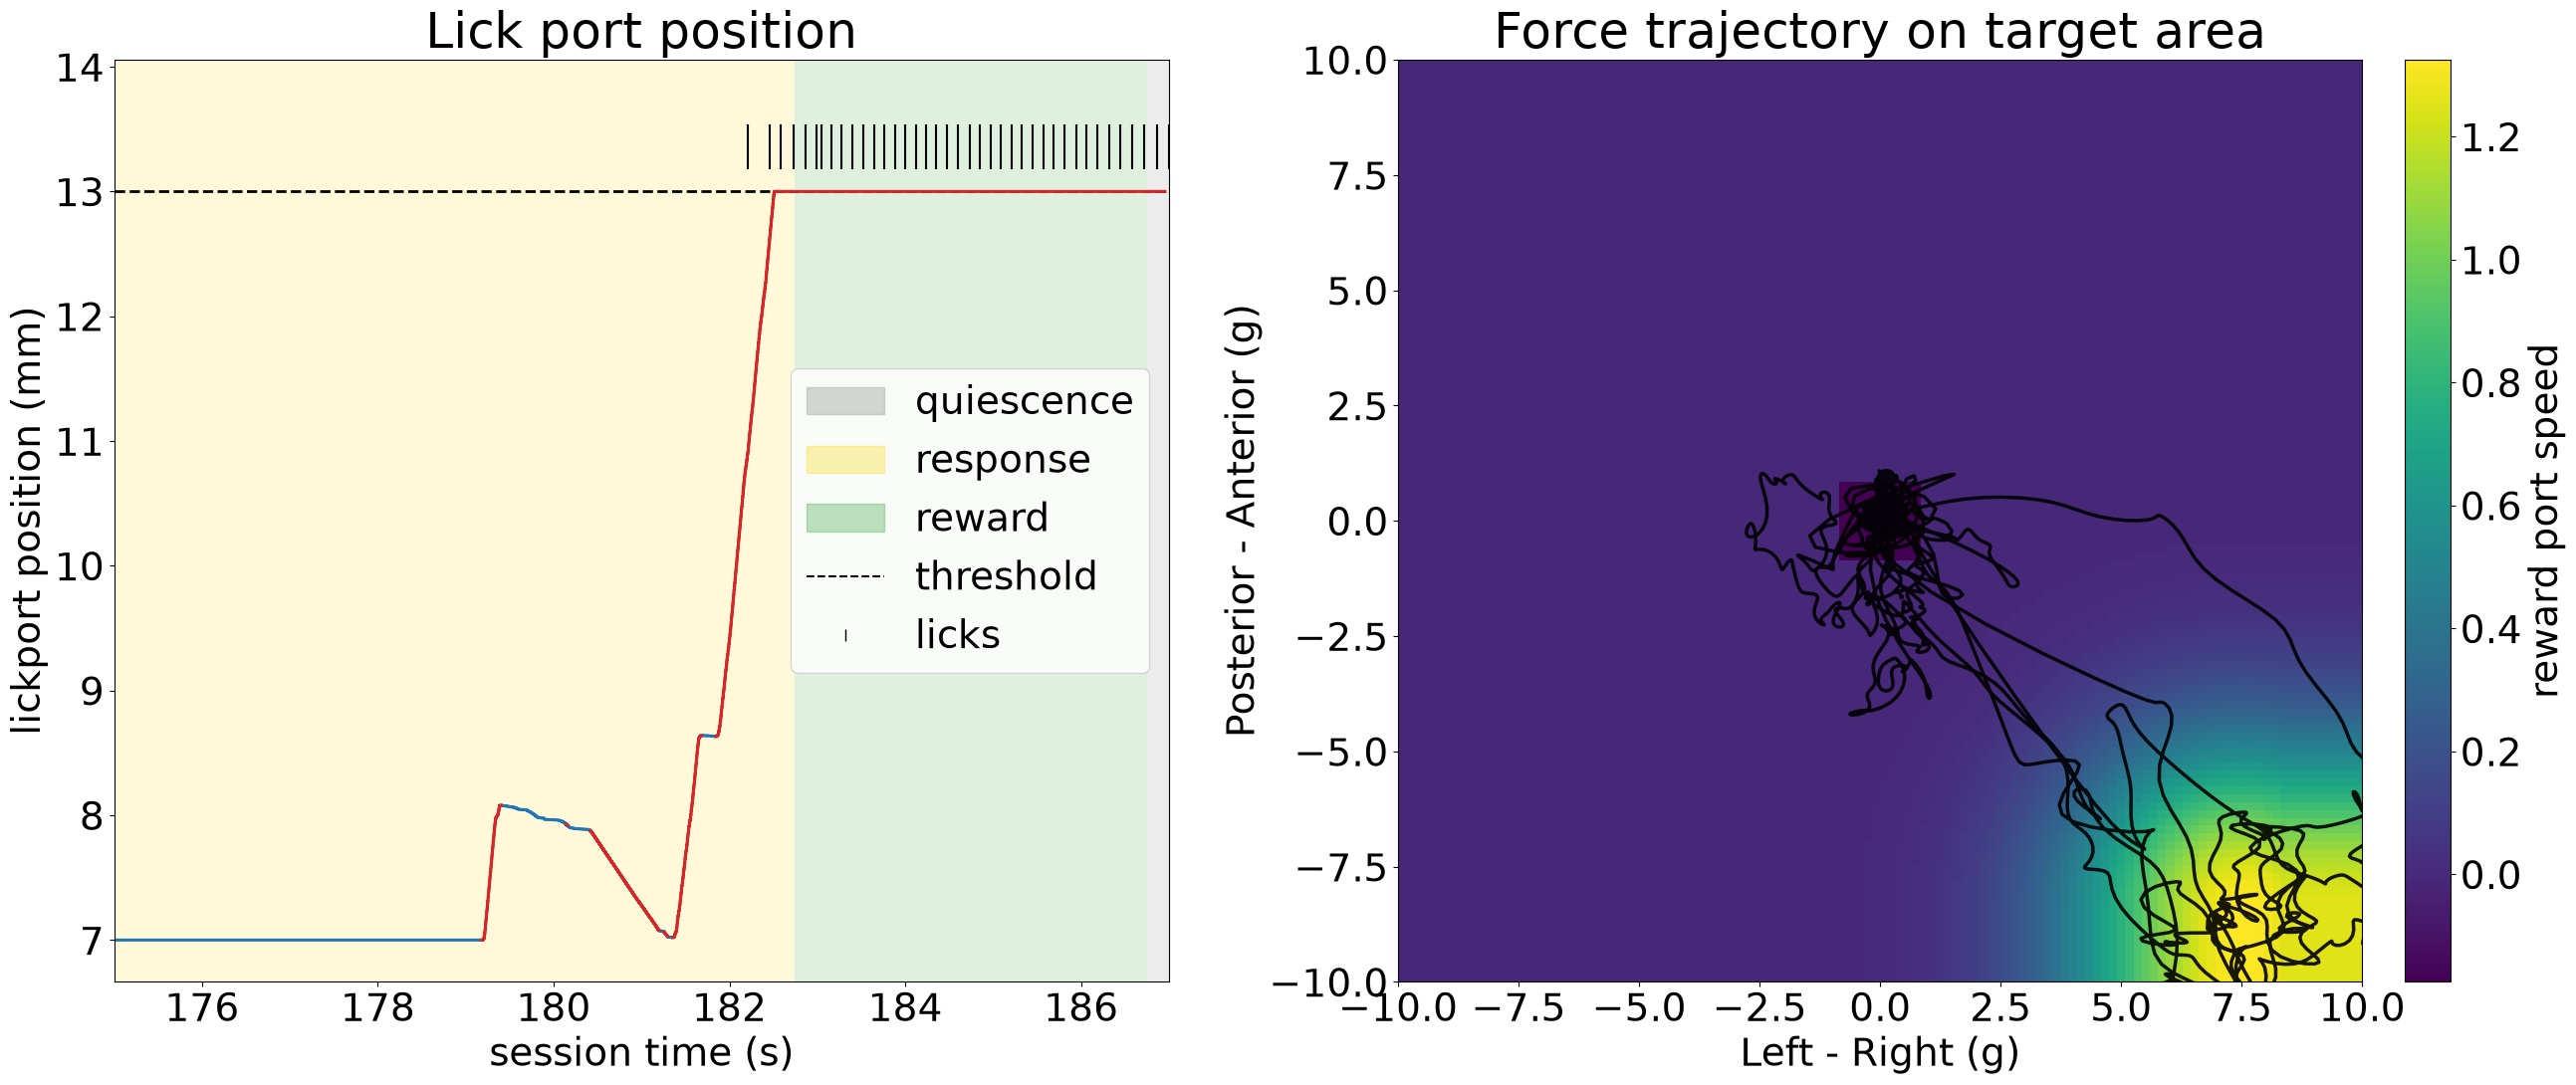

In [8]:
trial_of_interest = 14
block_of_interest = 2
t14_key = {'subject_id': subject_id_m029, 'session': session_m029, 'trial': trial_of_interest}
t15_key = {'subject_id': subject_id_m029, 'session': session_m029, 'trial': trial_of_interest + 1}
b2_key = {'subject_id': subject_id_m029, 'session': session_m029, 'block': block_of_interest}
trial_uniform_range = np.array([-1, 1, -1, 1]) * 10  # g
window_start, window_end = 175.0, 187.0  # session time (s) shown
color_continuous = 'tab:blue'
color_step = 'tab:red'
trajectory_linewidth = 2.5


def classify_lickport_motion(t, v, smooth_sigma_ms=20.0, percentile=75.0):
    '''Gaussian-smooth v(t), differentiate, and label samples whose |velocity| exceeds
    the given percentile (over this window) as step-like (True) vs continuous (False).'''
    sample_interval_s = np.median(np.diff(t))
    sigma_samples = bp.ms_to_samples_float(smooth_sigma_ms, sample_interval_s, minimum=1e-6)
    v_smooth = bp._filter_trace(v, 'gaussian', sigma=sigma_samples)
    velocity = np.gradient(v_smooth, t)
    threshold = np.percentile(np.abs(velocity), percentile)
    return np.abs(velocity) > threshold


# --- trial timing (absolute session time) ---
t14_start, t14_end = (experiment.SessionTrial() & t14_key).fetch1('trial_start_time', 'trial_end_time')
t14_start, t14_end = float(t14_start), float(t14_end)
t15_start = float((experiment.SessionTrial() & t15_key).fetch1('trial_start_time'))

go_time = float((experiment.TrialEvent() & {**t14_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))
threshold_time = float((experiment.TrialEvent() & {**t14_key, 'trial_event_type': 'threshold crossing'}).fetch1('trial_event_time'))
go15_time = float((experiment.TrialEvent() & {**t15_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))

abs_go14 = t14_start + go_time
abs_threshold14 = t14_start + threshold_time
abs_t14_end = t14_end  # == t15_start, no gap between trials
abs_go15 = t15_start + go15_time

# --- lick port position: trial 14 response+reward, then trial 15 quiescence ---
lp14_time, lp14_val = (experiment.TrialRewardPortPosition() & t14_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp14_time = np.asarray(lp14_time, float)
lp14_val = np.asarray(lp14_val, float)
threshold_position = lp14_val[np.clip(np.searchsorted(lp14_time, threshold_time, side='right') - 1, 0, len(lp14_val) - 1)]

extended14_mask = (lp14_time >= go_time) & (lp14_time <= (t14_end - t14_start))
lp15_time, lp15_val = (experiment.TrialRewardPortPosition() & t15_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp15_time = np.asarray(lp15_time, float)
lp15_val = np.asarray(lp15_val, float)
quiescence15_mask = (lp15_time >= 0) & (lp15_time <= go15_time)

lp_ext_df = pd.concat([
    pd.DataFrame({'t': t14_start + lp14_time[extended14_mask], 'v': lp14_val[extended14_mask]}),
    pd.DataFrame({'t': t15_start + lp15_time[quiescence15_mask], 'v': lp15_val[quiescence15_mask]}),
]).groupby('t', as_index=False).last()
t_lp_ext, v_lp_ext = lp_ext_df['t'].values, lp_ext_df['v'].values
is_step_ext = classify_lickport_motion(t_lp_ext, v_lp_ext)

lick_times14 = np.asarray((experiment.TrialEvent() & {**t14_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_times15 = np.asarray((experiment.TrialEvent() & {**t15_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_abs = np.concatenate([t14_start + lick_times14, t15_start + lick_times15])
lick_abs = lick_abs[(lick_abs >= window_start) & (lick_abs <= window_end)]

# --- force trace (LR/PA), trials 14 + 15, gaussian-filtered (sigma = 3 ms) ---
task_setting_id_t14 = (experiment.TaskSettings() * experiment.Block() & b2_key).fetch1('task_setting_id')
_, lr_idx_t14, pa_idx_t14, lr_sign_t14, pa_sign_t14 = bp._get_block_force_axes(
    experiment, subject_id_m029, session_m029, task_setting_id_t14)


def fetch_trial_lr_pa(trial_key, trial_start_abs):
    f0_time, f0_val = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                        & {**trial_key, 'force_axis_idx': 0}).fetch1('force_trace_time', 'force_trace_value')
    f1_val = (experiment.TrialForceTrace.TrialForceAxis() & {**trial_key, 'force_axis_idx': 1}).fetch1('force_trace_value')
    f0_time = np.asarray(f0_time, float)
    f0_val = np.asarray(f0_val, float) - np.median(f0_val)
    f1_val = np.asarray(f1_val, float) - np.median(f1_val)
    lr, pa = bp._lr_pa_traces([f0_val], [f1_val], lr_idx_t14, pa_idx_t14, lr_sign_t14, pa_sign_t14)
    sample_interval_s = bp._estimate_sample_interval([f0_time])
    sigma = bp.ms_to_samples_float(3.0, sample_interval_s, minimum=1e-6)
    (lr,), (pa,) = bp._filter_traces([lr[0]], [pa[0]], 'gaussian', sigma=sigma)
    return trial_start_abs + f0_time, lr, pa


f_time14, lr14, pa14 = fetch_trial_lr_pa(t14_key, t14_start)
f_time15, lr15, pa15 = fetch_trial_lr_pa(t15_key, t15_start)
f_time_all = np.concatenate([f_time14, f_time15])
lr_all = np.concatenate([lr14, lr15])
pa_all = np.concatenate([pa14, pa15])
window_mask = (f_time_all >= window_start) & (f_time_all <= window_end) & (f_time_all < abs_threshold14)
lr_smooth, pa_smooth = lr_all[window_mask], pa_all[window_mask]

# --- target area (block 2) ---
lut_t14, lut_extent_t14 = fetch_target_lut(subject_id_m029, session_m029, block_of_interest)
lut_disp_t14 = bp._pad_lut_to_range(lut_t14, lut_extent_t14, trial_uniform_range)

# --- plot (28pt labels / 36pt titles, as in the original) ---
FONT_LABEL_T14 = 28
FONT_TITLE_T14 = 36

fig, (ax_lp, ax_overlay) = plt.subplots(1, 2, figsize=(26, 11))

ax_lp.axvspan(abs_go14, abs_threshold14, color='gold', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_threshold14, abs_t14_end, color='tab:green', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_t14_end, abs_go15, color='gray', alpha=0.15, linewidth=0)
ax_lp.axhline(threshold_position, color='black', linestyle='--', linewidth=2)

ax_lp.step(t_lp_ext, np.where(~is_step_ext, v_lp_ext, np.nan), where='post', color=color_continuous, linewidth=2.2)
ax_lp.step(t_lp_ext, np.where(is_step_ext, v_lp_ext, np.nan), where='post', color=color_step, linewidth=2.2)

y0, y1 = v_lp_ext.min(), v_lp_ext.max()
tick_height = 0.06 * (y1 - y0)
ax_lp.eventplot(lick_abs, orientation='horizontal', lineoffsets=y1 + tick_height, linelengths=tick_height, colors='black')

ax_lp.set_xlim(window_start, window_end)
ax_lp.set_xlabel('session time (s)', fontsize=FONT_LABEL_T14)
ax_lp.set_ylabel('lickport position (mm)', fontsize=FONT_LABEL_T14)
ax_lp.set_title('Lick port position', fontsize=FONT_TITLE_T14)
ax_lp.tick_params(labelsize=FONT_LABEL_T14)
ax_lp.legend(handles=[
    bp.Patch(color='gray', alpha=0.3, label='quiescence'),
    bp.Patch(color='gold', alpha=0.3, label='response'),
    bp.Patch(color='tab:green', alpha=0.3, label='reward'),
    Line2D([0], [0], color='black', linestyle='--', label='threshold'),
    Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=8, label='licks'),
], loc='center right', fontsize=FONT_LABEL_T14)

im_target = ax_overlay.imshow(lut_disp_t14, extent=trial_uniform_range, origin='lower', cmap='viridis', aspect='auto')
ax_overlay.plot(lr_smooth, pa_smooth, '-', color='black', linewidth=trajectory_linewidth, alpha=0.9)
ax_overlay.set_xlim(trial_uniform_range[:2])
ax_overlay.set_ylim(trial_uniform_range[2:])
ax_overlay.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL_T14)
ax_overlay.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL_T14)
ax_overlay.set_title('Force trajectory on target area', fontsize=FONT_TITLE_T14)
ax_overlay.tick_params(labelsize=FONT_LABEL_T14)
cbar = fig.colorbar(im_target, ax=ax_overlay, fraction=0.046, pad=0.04)
cbar.set_label('reward port speed', fontsize=FONT_LABEL_T14)
cbar.ax.tick_params(labelsize=FONT_LABEL_T14)

plt.tight_layout(w_pad=4.0)

out_path = out_dir / 'trial14_lickport_vs_force_overlay_thick.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()